In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy

In [8]:
df = pd.read_json('data/isoflops_curves.json')
df

,parameters,compute_budget,final_loss
0,49999999,6.000000e+18,7.192785
1,78730505,6.000000e+18,6.750171
2,123969849,6.000000e+18,6.406640
3,195204177,6.000000e+18,6.154369
4,307370470,6.000000e+18,5.987783
...,...,...,...
67,12148905329,3.000000e+21,3.773188
68,20577985689,3.000000e+21,3.776239
69,34855279842,3.000000e+21,3.816546
70,59038360277,3.000000e+21,3.895885


In [9]:
df.dtypes

parameters          int64
compute_budget    float64
final_loss        float64
dtype: object

In [10]:
df.nunique()

parameters        68
compute_budget     9
final_loss        72
dtype: int64

In [15]:
df.groupby('compute_budget').size()

compute_budget
6.000000e+18    8
1.000000e+19    8
3.000000e+19    8
6.000000e+19    8
1.000000e+20    8
3.000000e+20    8
6.000000e+20    8
1.000000e+21    8
3.000000e+21    8
dtype: int64

In [22]:
df.groupby('compute_budget')['parameters'].agg(['min', 'max'])

,min,max
compute_budget,,
6.000000e+18,49999999,1200000000
1.000000e+19,83333333,2000000000
3.000000e+19,249999999,6000000000
6.000000e+19,499999999,12000000000
1.000000e+20,833333333,20000000000
3.000000e+20,249999999,10000000000
6.000000e+20,499999999,20000000000
1.000000e+21,833333333,33333333333
3.000000e+21,2499999999,100000000000


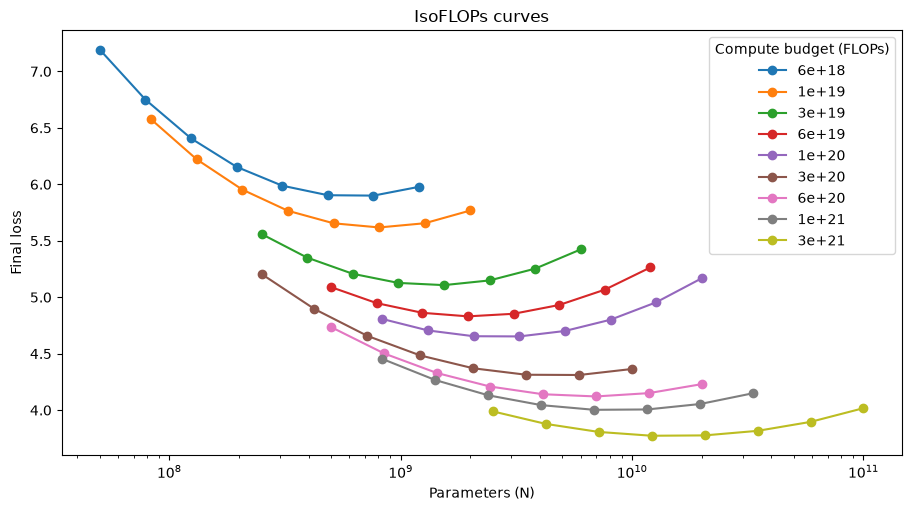

In [56]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for budget, sub_df in df.groupby("compute_budget"):
    ax.plot(sub_df['parameters'], sub_df['final_loss'], marker="o", label=budget)
ax.set_xscale('log')
ax.legend(title='Compute budget (FLOPs)')
ax.set_title('IsoFLOPs curves')
ax.set_xlabel('Parameters (N)')
ax.set_ylabel('Final loss')
plt.show()

In [61]:
from numpy.typing import NDArray
import numpy as np

def curve_func(x: float | NDArray[np.float64], a: float, h: float, k: float) -> float | NDArray[np.float64]:
    return a * (x - h)**2 + k

In [65]:
x = np.array([8., 9., 10.])
a = 0.5
h = 9.0
k = 3.0
actual = curve_func(x, a, h, k)
expected = [3.5, 3.0, 3.5]
np.testing.assert_allclose(actual, expected)

In [80]:
import scipy

df_6e18 = df.groupby("compute_budget").get_group(6e18)
x = np.log10(df_6e18['parameters'].to_numpy())
y = df_6e18['final_loss'].to_numpy()
# Guess initially
h = x[np.argmin(y)] # base it on position of lowest loss
k = y.min() # lowest loss
a = 1 # something small and positive

popt, pcov = scipy.optimize.curve_fit(curve_func, x, y, p0=[a, h, k])

In [92]:
a_fit, h_fit, k_fit = popt

In [93]:
np.sqrt(np.diag(pcov)) # standard errors for a, h, k

array([0.01302842, 0.00521454, 0.00314615])

In [95]:
grid = np.linspace(x.min(), x.max(), 200)
vals = curve_func(grid, a_fit, h_fit, k_fit)

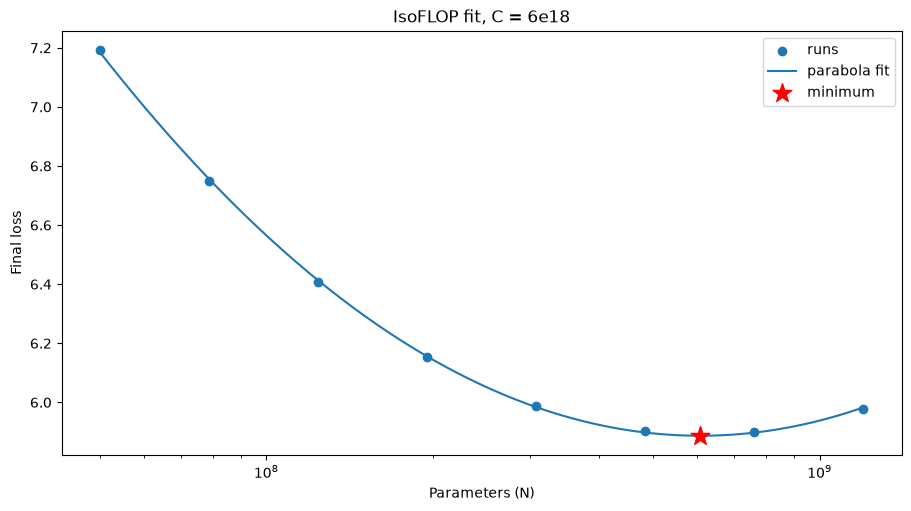

In [96]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.scatter(10**x, y, label="runs")
ax.plot(10**grid, vals, label="parabola fit")
ax.scatter(10**h_fit, k_fit, marker="*", s=200, color="red", zorder=3, label="minimum")
ax.set_xscale("log")
ax.set_xlabel("Parameters (N)")
ax.set_ylabel("Final loss")
ax.set_title("IsoFLOP fit, C = 6e18")
ax.legend()
plt.show()

In [99]:
rows = []
for budget, group in df.groupby("compute_budget"):
    x = np.log10(group['parameters'].to_numpy())
    y = group['final_loss'].to_numpy()
    h = x[np.argmin(y)] # base it on position of lowest loss
    k = y.min() # lowest loss
    a = 1 # something small and positive
    popt, pcov = scipy.optimize.curve_fit(curve_func, x, y, p0=[a, h, k])
    a_fit, h_fit, k_fit = popt
    std_err = np.sqrt(np.diag(pcov))
    data = {'compute_budget': budget, 'curvature': a_fit, 'log10_n_opt': h_fit, 'loss_opt': k_fit, 'n_opt': 10**h_fit, 'log10_n_opt_err': std_err[1], 'loss_opt_err': std_err[2]}
    rows.append(data)
results = pd.DataFrame(rows)

In [100]:
results

,compute_budget,curvature,log10_n_opt,loss_opt,n_opt,log10_n_opt_err,loss_opt_err
0,6.000000e+18,1.102991,8.784062,5.886921,6.082215e+08,0.005215,0.003146
1,1.000000e+19,0.989880,8.903440,5.614589,8.006448e+08,0.002956,0.002016
2,3.000000e+19,0.804003,9.149548,5.105120,1.411068e+09,0.000634,0.000664
3,6.000000e+19,0.717823,9.302878,4.828759,2.008531e+09,0.001359,0.001212
4,1.000000e+20,0.666122,9.417777,4.644821,2.616838e+09,0.002699,0.001666
5,3.000000e+20,0.569817,9.653384,4.300968,4.501780e+09,0.008194,0.002982
6,6.000000e+20,0.490111,9.817431,4.118066,6.567962e+09,0.004234,0.001751
7,1.000000e+21,0.442293,9.933404,3.996966,8.578362e+09,0.002191,0.001077
8,3.000000e+21,0.363712,10.176074,3.768938,1.499942e+10,0.001285,0.000741


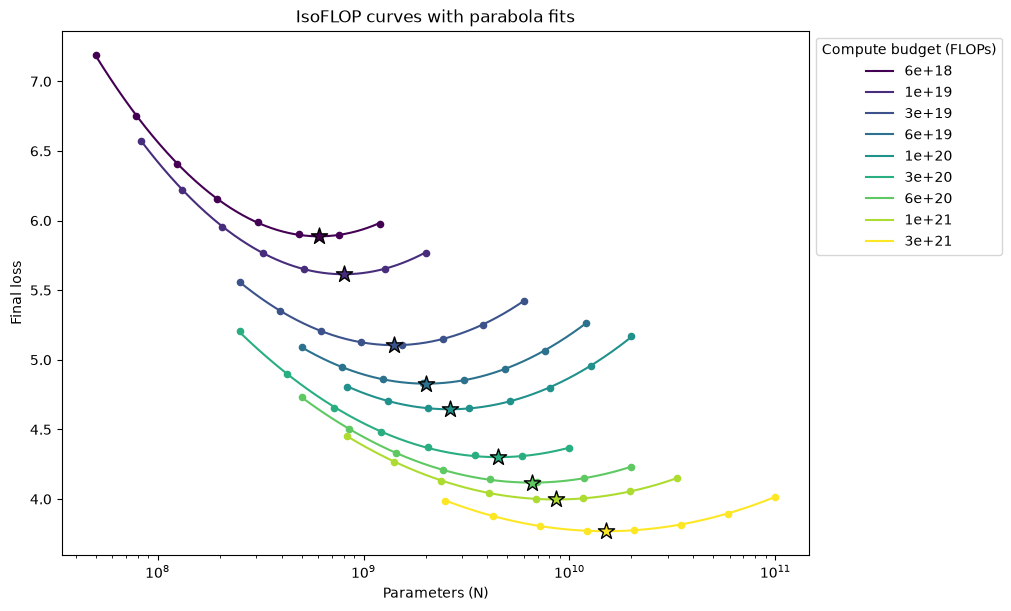

In [103]:
import matplotlib as mpl

fit = results.set_index("compute_budget")
colors = mpl.colormaps["viridis"](np.linspace(0, 1, len(fit)))

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
for color, (budget, group) in zip(colors, df.groupby("compute_budget")):
    row = fit.loc[budget]
    x = np.log10(group["parameters"].to_numpy())
    grid = np.linspace(x.min(), x.max(), 200)
    vals = curve_func(grid, row["curvature"], row["log10_n_opt"], row["loss_opt"])

    ax.scatter(group["parameters"], group["final_loss"], color=color, s=20)
    ax.plot(10**grid, vals, color=color, label=f"{budget:.0e}")
    ax.scatter(row["n_opt"], row["loss_opt"], color=color, marker="*", s=150, edgecolor="black", zorder=3)

ax.set_xscale("log")
ax.set_xlabel("Parameters (N)")
ax.set_ylabel("Final loss")
ax.set_title("IsoFLOP curves with parabola fits")
ax.legend(title="Compute budget (FLOPs)", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

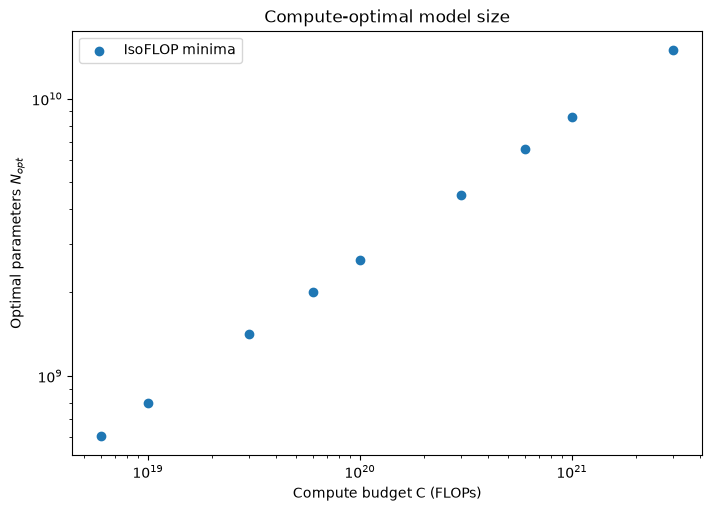

In [104]:
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ax.scatter(results["compute_budget"], results["n_opt"], label="IsoFLOP minima")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Compute budget C (FLOPs)")
ax.set_ylabel(r"Optimal parameters $N_{opt}$")
ax.set_title("Compute-optimal model size")
ax.legend()
plt.show()

In [107]:
def isoflops_fit(C: float | NDArray[np.float64], m: float, b: float) -> float | NDArray[np.float64]:
    return 10**b * C**m

In [113]:
x = np.log10(results["compute_budget"])
y = np.log10(results["n_opt"])
res = scipy.stats.linregress(x, y)
m, b, r_squared = res.slope, res.intercept, res.rvalue**2

In [112]:
res

LinregressResult(slope=np.float64(0.5145794846229214), intercept=np.float64(-0.8755980551393474), rvalue=np.float64(0.9999719497909371), pvalue=np.float64(3.848589237597388e-16), stderr=np.float64(0.0014567855782276226), intercept_stderr=np.float64(0.02928691912554254))

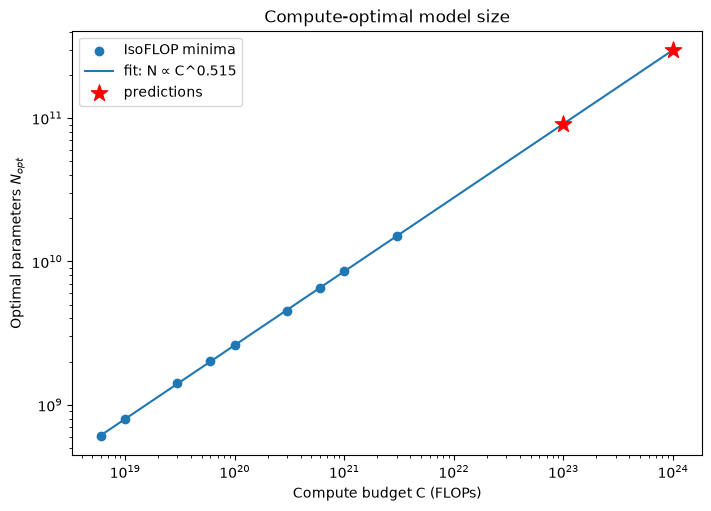

In [122]:
targets = np.array([1e23, 1e24])
c_grid = np.logspace(np.log10(results["compute_budget"].min()), np.log10(targets.max()), 200)

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ax.scatter(results["compute_budget"], results["n_opt"], label="IsoFLOP minima", zorder=3)
ax.plot(c_grid, isoflops_fit(c_grid, m, b), label=f"fit: N ∝ C^{m:.3f}")
ax.scatter(targets, isoflops_fit(targets, m, b), marker="*", s=150, color="red",
           zorder=3, label="predictions")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Compute budget C (FLOPs)")
ax.set_ylabel(r"Optimal parameters $N_{opt}$")
ax.set_title("Compute-optimal model size")
ax.legend()
plt.show()

In [115]:
print(isoflops_fit(targets, m, b))

[9.11444212e+10 2.98064035e+11]


In [118]:
results['d_opt'] = results['compute_budget'] / (6 * results['n_opt'])
results

,compute_budget,curvature,log10_n_opt,loss_opt,n_opt,log10_n_opt_err,loss_opt_err,d_opt
0,6.000000e+18,1.102991,8.784062,5.886921,6.082215e+08,0.005215,0.003146,1.644138e+09
1,1.000000e+19,0.989880,8.903440,5.614589,8.006448e+08,0.002956,0.002016,2.081656e+09
2,3.000000e+19,0.804003,9.149548,5.105120,1.411068e+09,0.000634,0.000664,3.543414e+09
3,6.000000e+19,0.717823,9.302878,4.828759,2.008531e+09,0.001359,0.001212,4.978764e+09
4,1.000000e+20,0.666122,9.417777,4.644821,2.616838e+09,0.002699,0.001666,6.369010e+09
5,3.000000e+20,0.569817,9.653384,4.300968,4.501780e+09,0.008194,0.002982,1.110672e+10
6,6.000000e+20,0.490111,9.817431,4.118066,6.567962e+09,0.004234,0.001751,1.522542e+10
7,1.000000e+21,0.442293,9.933404,3.996966,8.578362e+09,0.002191,0.001077,1.942873e+10
8,3.000000e+21,0.363712,10.176074,3.768938,1.499942e+10,0.001285,0.000741,3.333462e+10


In [119]:
x = np.log10(results["compute_budget"])
y = np.log10(results["d_opt"])
res = scipy.stats.linregress(x, y)
d_m, d_b, d_r_squared = res.slope, res.intercept, res.rvalue**2

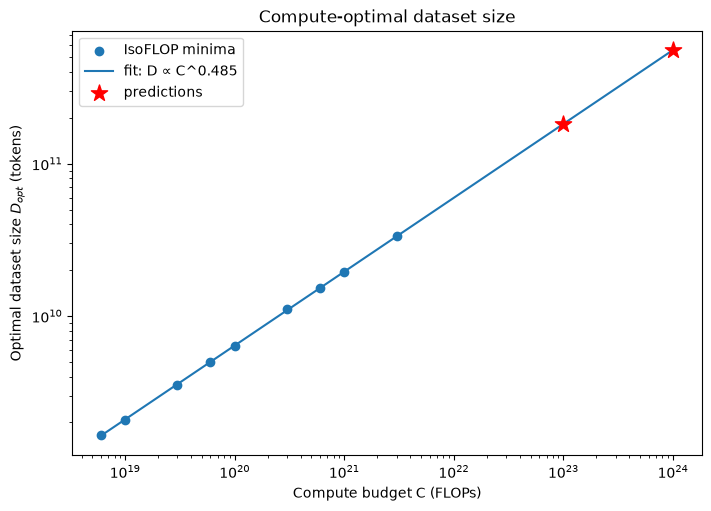

In [120]:
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ax.scatter(results["compute_budget"], results["d_opt"], label="IsoFLOP minima", zorder=3)
ax.plot(c_grid, isoflops_fit(c_grid, d_m, d_b), label=f"fit: D ∝ C^{d_m:.3f}")
ax.scatter(targets, isoflops_fit(targets, d_m, d_b), marker="*", s=150, color="red",
           zorder=3, label="predictions")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Compute budget C (FLOPs)")
ax.set_ylabel(r"Optimal dataset size $D_{opt}$ (tokens)")
ax.set_title("Compute-optimal dataset size")
ax.legend()
plt.show()

In [121]:
print(isoflops_fit(targets, d_m, d_b))

[1.82859976e+11 5.59163962e+11]


In [1]:
from cs336_scaling.selfstudy import runner
from cs336_scaling.training.run import default_training_config

eid = runner.submit(default_training_config(), label="smoke")
runner.wait(poll_seconds=15)
runner.results_df()

/Users/pjurczen/repo/cs336-assignment3-scaling/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


experiment 1 completed: final val loss 9.1138, trained 7s, charged 7s


,experiment_id,label,kind,status,hidden_size,num_hidden_layers,num_attention_heads,intermediate_size,train_batch_size,peak_lr,...,max_runtime_seconds,model_seed,model_params,training_seconds,charged_seconds,final_val_loss,val_losses,submitted_at,finished_at,error
0,1,smoke,scaling,completed,448,9,7,1280,128,0.0003,...,30.0,0,51389888,7.194642,7.194642,9.113843,"[10.297824, 10.084743, 9.868369, 9.662651, 9.5...",2026-11-25T18:47:16+00:00,2026-11-25T18:48:32+00:00,None
